1. Propagate ABC classes from Yao et al. scRNA-seq brain atlas
2. Remove clusters labelled as non-HY classes 
3. Manual removal of fishy cells/clusters that were identified later in previous runs of the pipeline
4. Removal of singleton clusters


While steps 3 and 4 were previously done later in the pipeline, the SCVI embedding obtained in the next module will benefit from the absence of those cells. 

Hence, we decided to break the natural time-course here, and remove those cells.

__This notebook benefits from GPU accessibility__

In [1]:
# No need to restart notebook when editing custom packages
%load_ext autoreload
%autoreload 2

In [42]:
from pathlib import Path
import warnings
import gc 
import tempfile
import os 

warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd
from dotenv import dotenv_values
import scanpy as sc
import matplotlib.pyplot as plt
sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)

from hm3d_utils.clustering import propagate_labels_within_dataset, remove_singleton_clusters
from hm3d_utils.plotting import plot_label_propagation_summary

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
MODELDIR = DATADIR / '4_HY' / 'all_HY'
DATASETS_DIR = MODELDIR / "datasets"
PLOTS_DIR = MODELDIR / 'plots'
CELL_HISTORY = DATADIR / "qc_log.csv" #QC log

### Load and merge datasets

In [4]:
adata = sc.read_h5ad(Path(DATASETS_DIR, 'raw.h5ad',))
embed_only = sc.read_h5ad(Path(DATASETS_DIR, 'embed_only.h5ad'),)

In [5]:
adata.obsm = embed_only[adata.obs_names].obsm
adata.uns = {k: v for k, v in embed_only.uns.items() if k in {'tsne', 'umap', 'neighbors'}}
adata.obsp = embed_only.obsp

del embed_only
gc.collect() # free up mem
adata

AnnData object with n_obs × n_vars = 1725062 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

### Let's propagate 'class_id_label'

In [6]:
propagation_label = 'class_id_label'
propagation_key = 'ABC_class'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)

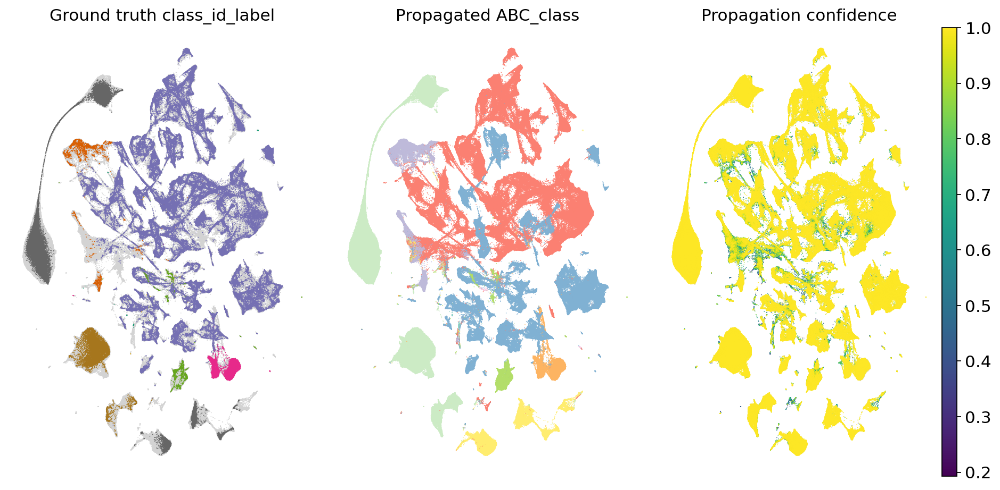

In [7]:
plot_label_propagation_summary(
    adata,
    propagation_label,
    propagation_key,
    save_dir = PLOTS_DIR)

### Let's remove non-HY clusters as defined by ABC

In [8]:
nn_classes = ['30 Astro-Epen', '31 OPC-Oligo', '33 Vascular', '34 Immune',]

valid_classes = [
    label for label in set(adata.obs[f'{propagation_key}_propagated'].dropna()) 
    if 'HY' in label
] + nn_classes

sorted(valid_classes)

['11 CNU-HYa GABA',
 '12 HY GABA',
 '13 CNU-HYa Glut',
 '14 HY Glut',
 '15 HY Gnrh1 Glut',
 '16 HY MM Glut',
 '30 Astro-Epen',
 '31 OPC-Oligo',
 '33 Vascular',
 '34 Immune']

In [9]:
invalid_classes_mask = ~adata.obs[f'{propagation_key}_propagated'].isin(valid_classes)
low_confidence_mask = adata.obs[f'{propagation_key}_confidence'] < 0.5

# Remove cells with low propagation confidence or cells that are not a valid class
remove_mask = (invalid_classes_mask | low_confidence_mask)
keep_mask = ~ remove_mask

adata.obs["to_be_removed"] = remove_mask


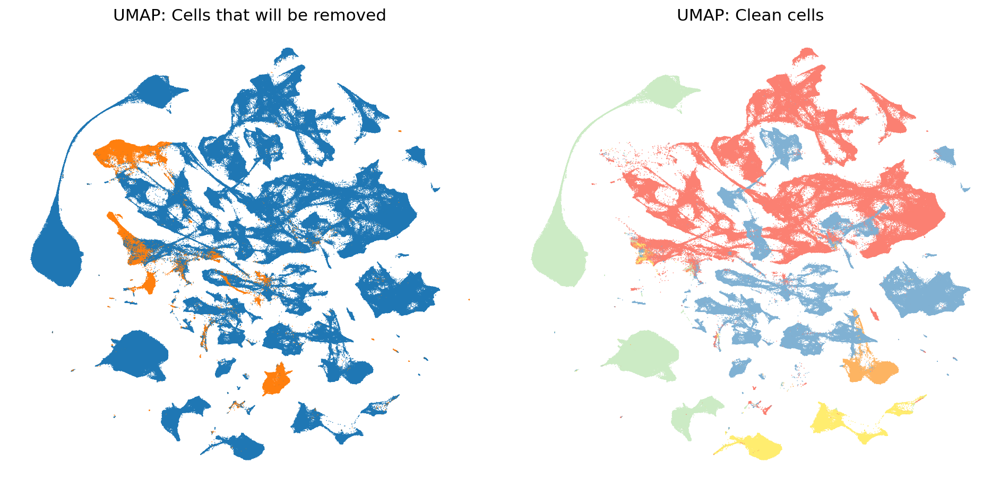

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(12, 6))


sc.pl.umap(
    adata,
    color='to_be_removed',
    size=2,
    ax=axes[0],
    show=False,  # Prevents immediate display, allowing combined plots
    legend_loc=None,
    vmax=0.5
)
axes[0].set_title(f"UMAP: Cells that will be removed")


sc.pl.umap(
    adata[keep_mask],
    color=f'{propagation_key}_propagated',
    #palette='tab20',  # Example alternative palette; adjust as needed
    size=2,
    ax=axes[1],
    show=False,
    legend_loc=None
)
axes[1].set_title(f"UMAP: Clean cells")

# Adjust layout and display the final figure
plt.tight_layout()
plt.show()

fig.savefig(PLOTS_DIR / f'HY_filtered.png')

In [11]:
# keep non-HY removed cell IDs for QC log
non_hy_removed = adata[remove_mask].obs_names.values

### let's remove the cells

In [12]:
adata = adata[keep_mask].copy()
adata.uns = {k: v for k, v in adata.uns.items() if 'color' not in k}

gc.collect() # free up mem

44308

# Manual Removal

## Non-HY stragglers

In later steps we realized that there was a cluster of cells expressing Shox2, which is usually not expressed in the HY. 

It also did not match any propagated ABC classes very well.

Hence, we removed the cluster as likely non-HY cells. 

In [13]:
def rearrange_cellid(s: str) -> str:
    """ helper function to translate from old to new cellID naming convention"""
    left, right = s.split("_", 1)
    return f"{right}_{left}"

In [14]:
nonhy = pd.read_csv("resources/non_hy_cluster_cells.csv")
nonhy = (
    nonhy["0"]
    .apply(rearrange_cellid)
    .rename("CellID")
    .to_frame()
    .set_index("CellID")
)

In [15]:
# Get CellIDs to remove
remove_ids = set(nonhy.index)

# Get remove mask
nonhy_manual_remove_mask = adata.obs["CellID"].isin(remove_ids)
nonhy_manual_keep_mask = ~nonhy_manual_remove_mask

# keep cell IDs for QC log
nonhy_manual_removed_cells = adata[nonhy_manual_remove_mask].obs_names.values

In [16]:
# Remove those cells
adata = adata[nonhy_manual_keep_mask].copy()
gc.collect() # free up mem

1553

## Removal of likely doublet cluster

After we had obtained clusterings for the classes of OPCs, Immune cells as well as Astro-Epen cells, we found a cluster of vascular cells that simultaneously expressed marker genes for smooth muscle cells, pericytes as well as endothelial cells. 

Below, plotting marker genes for pericytes, smooth muscle cells as well as endothelial cells from [here](https://www.nature.com/articles/nature25739)

In [17]:
vasc_adata = adata[adata.obs["ABC_class_propagated"].str.contains("Vascular")].copy()

print("normalizing")
sc.pp.normalize_total(vasc_adata, target_sum = 10_000) 
sc.pp.log1p(vasc_adata, base=2, )

normalizing


In [18]:
#plt.hist2d(vasc_adata.obsm["X_umap"][:, 0], vasc_adata.obsm["X_umap"][:, 1])

In [19]:
# zoom into the interesting region of the umap
vasc_adata = vasc_adata[(vasc_adata.obsm["X_umap"][:, 0] > 10) & (vasc_adata.obsm["X_umap"][:, 1] < -6)].copy()

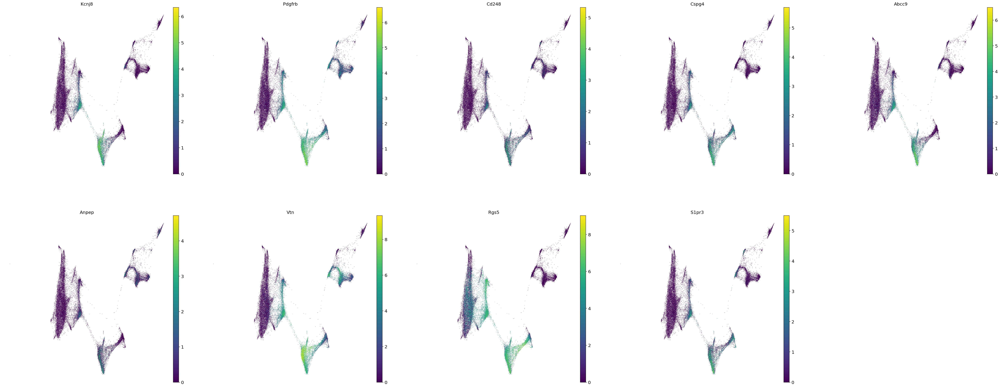

In [20]:
peri_genes = ["Kcnj8", "Pdgfrb", "Cd248", "Cspg4", "Abcc9", "Anpep", "Vtn", "Rgs5", "S1pr3"]

sc.pl.umap(vasc_adata, color = peri_genes, ncols = 5,)

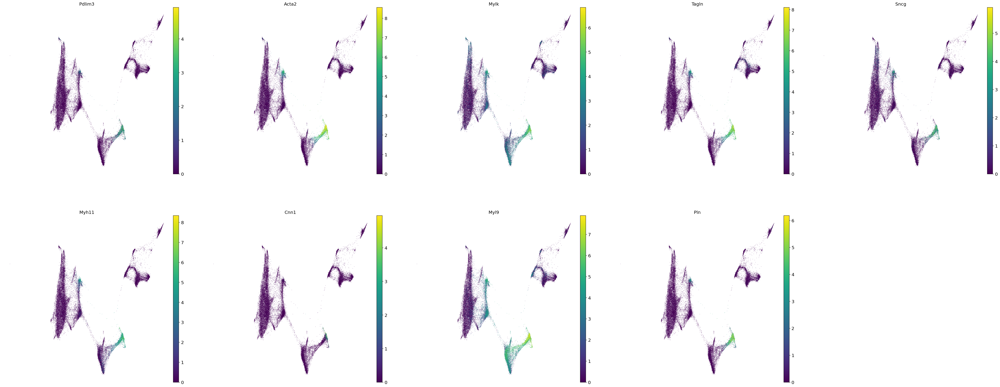

In [21]:
smc_genes = ["Pdlim3", "Acta2", "Mylk", "Tagln", "Sncg", "Myh11", "Cnn1", "Myl9", "Pln"]

sc.pl.umap(vasc_adata, color = smc_genes, ncols = 5,)

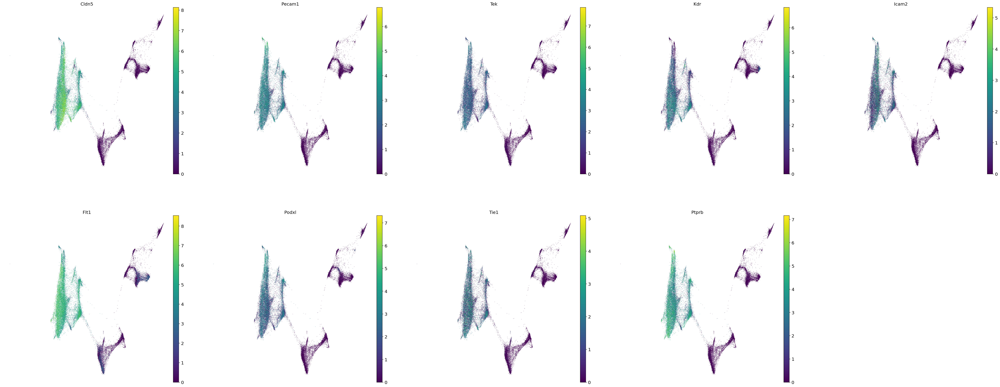

In [22]:
ec_genes = ["Cldn5", "Pecam1", "Tek", "Kdr", "Icam2", "Flt1", "Podxl", "Tie1", "Ptprb"]

sc.pl.umap(vasc_adata, color = ec_genes, ncols = 5,)


Importantly, marker genes for this cluster were also not specific as they were always shared for either smooth muscle cells, pericytes or endothelial cells. 

Below, the 3 most specific marker genes for that cluster of cells vs its vascular sister clusters (SMCs + PCs + ECs + fibroblasts/VLMCs) as well as the marker genes for the dubious cluster's subclusters which would be a split between top/down. 

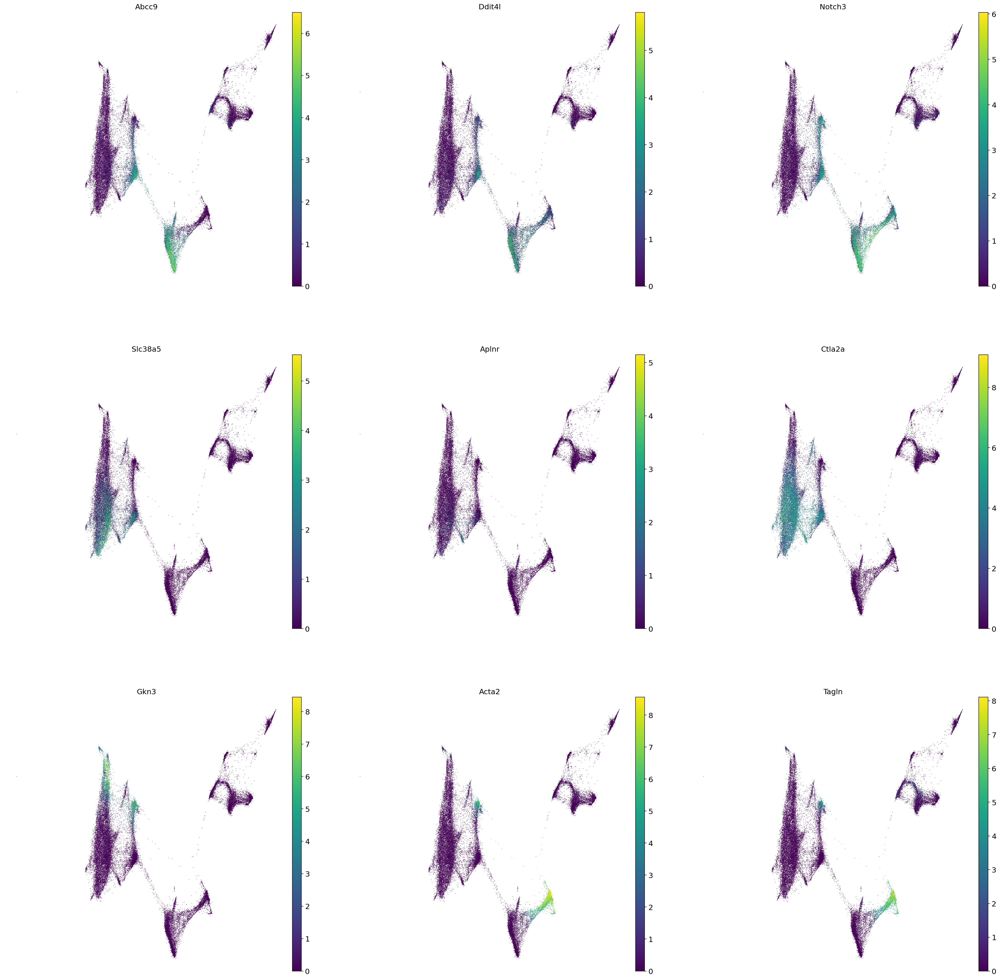

In [23]:
marker_genes = ["Abcc9", "Ddit4l", "Notch3", # top specific to genes to that cluster vs all vascular sister clusters 
    "Slc38a5", "Aplnr", "Ctla2a", # top specific genes down vs top
    "Gkn3", "Acta2", "Tagln"] # top specific genes top vs down

sc.pl.umap(vasc_adata, color = marker_genes, ncols=3)

Furthermore, we could not find a cell type simultaneously expressing marker genes for all of the three subclasses of cells, suggesting that the dubious cluster of cells could potentially be comprised of doublets. 

Given the above, we decided to remove the cluster from the data. 

The following csv was derived from a prelimiary clustering run.

In [24]:
vasc_clusters = pd.read_csv("resources/initial_vascular_clustering_for_cell_removal.csv", index_col=0)
vasc_clusters.index = pd.Series(vasc_clusters.index).apply(lambda x: rearrange_cellid(x))

In [25]:
vasc_clusters

,L2_clustering1
SC1-01_SAMN18754353_AACCTTTAGCGTGAAC,G17-9
SC1-01_SAMN18754353_AGAAGTAGTTATGTCG,G17-11
SC1-01_SAMN18754353_AGCATCACATCCAACA,G17-9
SC1-01_SAMN18754353_AGCGCTGGTCTTGAGT,G17-9
SC1-01_SAMN18754353_ATCACTTAGAACTTCC,G17-10
...,...
SC2-25_SAMN46505609_TCCCGTTAGCGCCTAA,G17-11
SC2-25_SAMN46505609_TCCTCACAGTAAGGGC,G17-8
SC2-25_SAMN46505609_TCGCATTGTTAAGCTG,G17-8
SC2-25_SAMN46505609_TGATGACTCGAAGCGG,G17-11


In [26]:
vasc_adata.obs["vasc_clusters"] = np.nan

In [27]:
# Get the common indices
common_idx = vasc_adata.obs.index.intersection(vasc_clusters.index)

# Assign only to the common indices
vasc_adata.obs.loc[common_idx, "vasc_clusters"] = vasc_clusters.loc[common_idx, "L2_clustering1"]

... storing 'vasc_clusters' as categorical


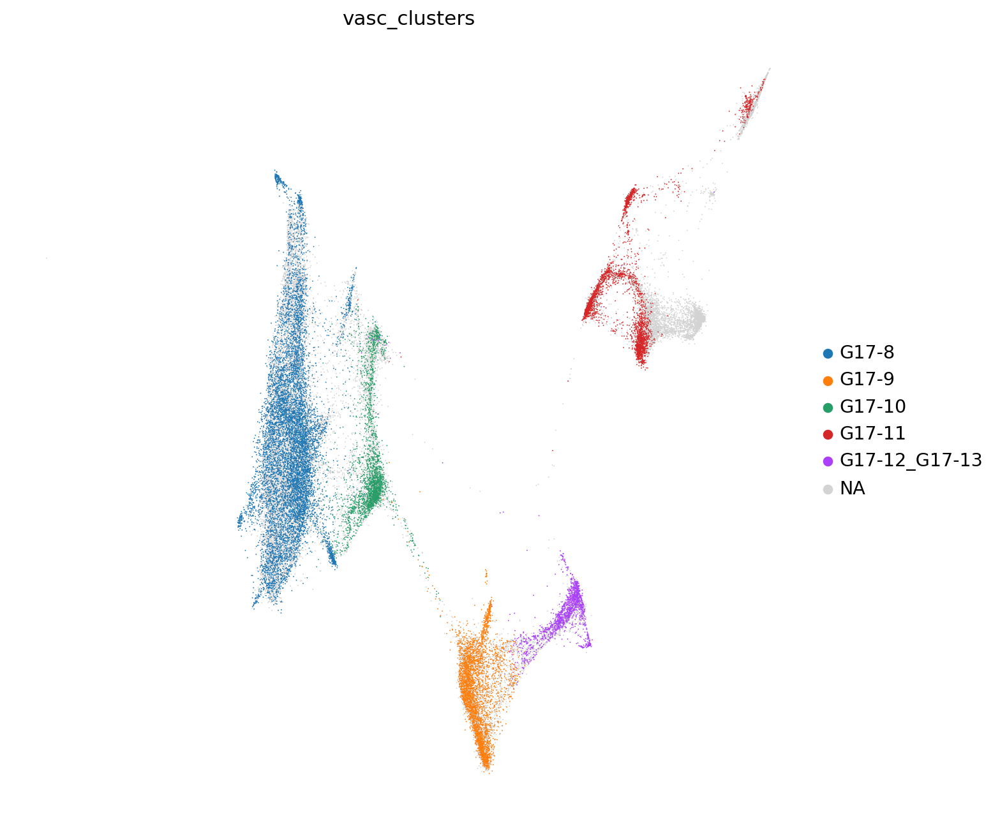

In [28]:
sc.pl.umap(vasc_adata, color = "vasc_clusters")

Let's remove those cells

In [29]:
doublet_cells = vasc_adata[vasc_adata.obs.vasc_clusters == "G17-10"].obs_names.values

doublet_manual_remove_mask = adata.obs_names.isin(doublet_cells)
doublet_manual_keep_mask = ~doublet_manual_remove_mask

# keep cell names for QC log
doublet_manual_remove_cells = adata[doublet_manual_remove_mask].obs_names.values

In [30]:
adata = adata[doublet_manual_keep_mask].copy()

In [31]:
del vasc_adata
gc.collect() # free up mem

141223

# Removal of singleton clusters 

Next, there were always some stragglers that avoided QC.

Hence, we removed them by getting high-resolution dummy clusterings and removing all clusters that were comprised of less than 5 cells.

For this, we split the adata into neuronal and non-neuronal cells.

In [32]:
non_neuronal_mask = adata.obs['ABC_class_propagated'].isin(nn_classes)

neuronal_subset = adata[~non_neuronal_mask].copy()
nn_subset = adata[non_neuronal_mask].copy()

The following functions return the filtered objects

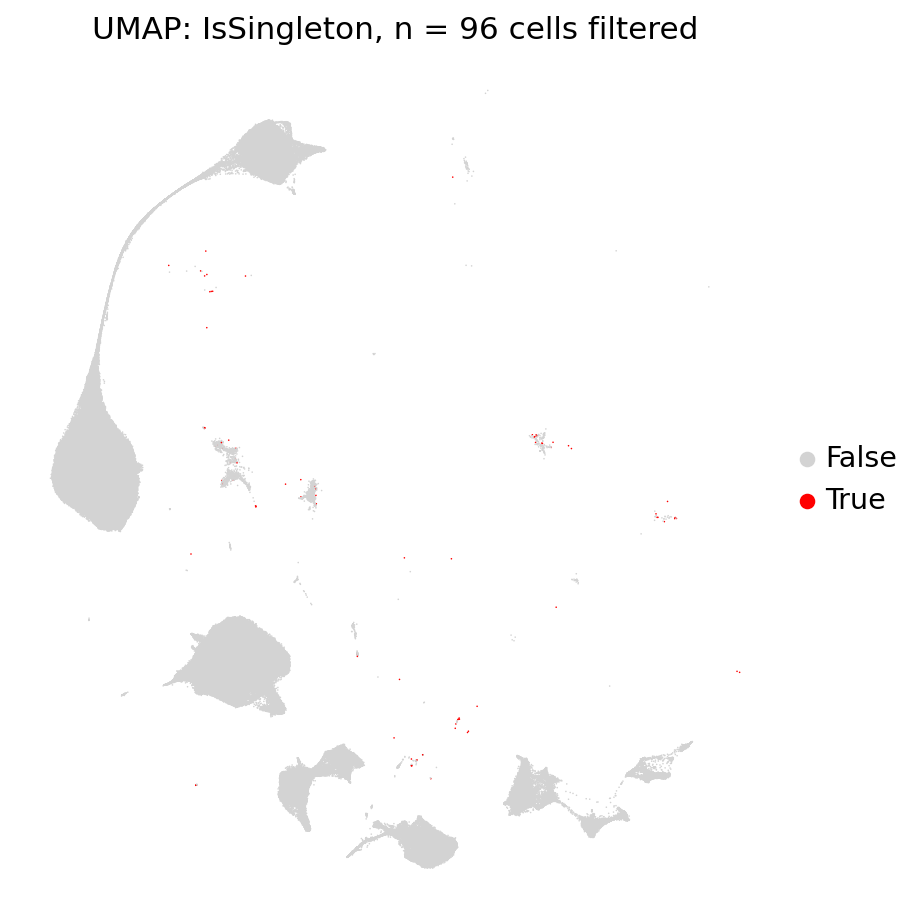

In [33]:
# Remove singleton clusters

nn_subset = remove_singleton_clusters(adata = nn_subset, 
    min_cluster_size = 5, # clusters with less than this number will be removed
    n_iterations = 2, # clustering iterations using default leiden
    plot_umap = True,
    umap_save_path = Path(PLOTS_DIR, f"non_neuronal_singletons_removed"),
    ) 

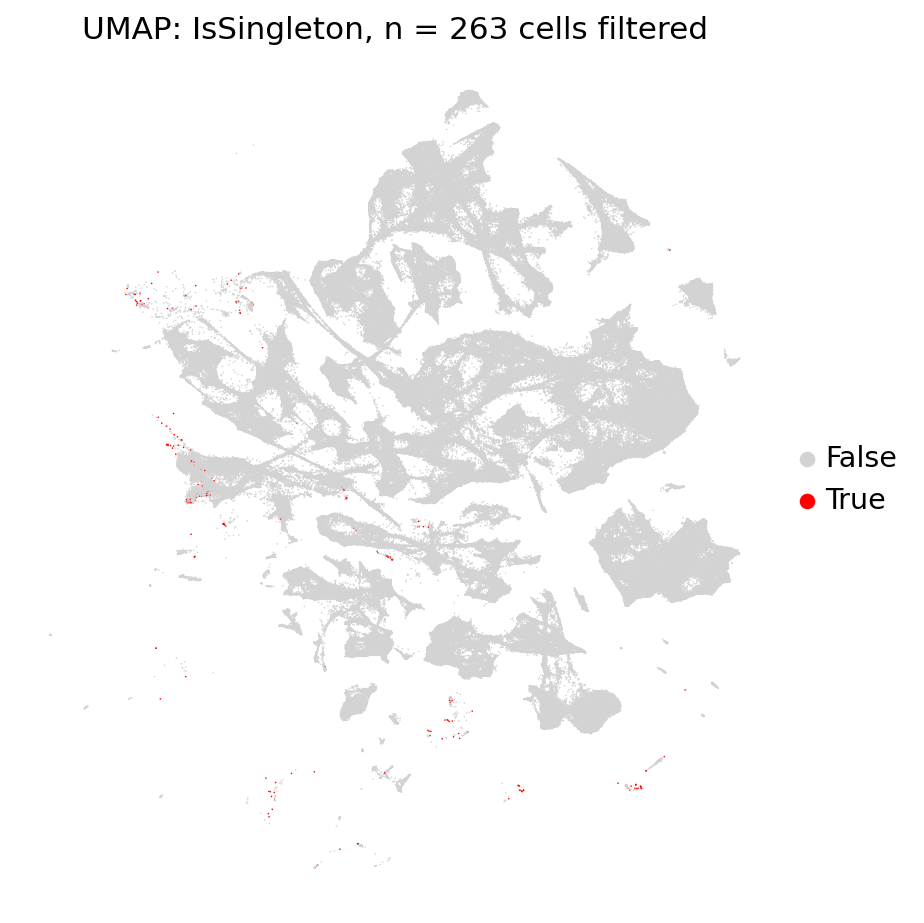

In [34]:
neuronal_subset = remove_singleton_clusters(adata = neuronal_subset, 
    min_cluster_size = 5, # clusters with less than this number will be removed
    n_iterations = 2, # clustering iterations using default leiden
    plot_umap = True,
    umap_save_path = Path(PLOTS_DIR, f"neuronal_singletons_removed"),
    ) 

In [35]:
#First get singleton cells for QC log 
singleton_cluster_cells = list(set(adata.obs_names) - set(neuronal_subset.obs_names) - set(nn_subset.obs_names))

In [36]:
del neuronal_subset, nn_subset
gc.collect() # free up mem

5795

### Save out filtered data

In [37]:
# remove singleton cells 
adata = adata[~adata.obs_names.isin(singleton_cluster_cells)]

In [38]:
adata

View of AnnData object with n_obs × n_vars = 1591408 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

In [39]:
adata.write_h5ad(Path(DATASETS_DIR, f'HY_raw_embed.h5ad'))

In [40]:
# free up mem 
del adata 
gc.collect()

0

# let's update the QC log

In [54]:
# Load existing file
qc_log_df = pd.read_csv(CELL_HISTORY)

qc_log_df["IsNonHy"] = False 
qc_log_df.loc[qc_log_df["CellID"].isin(non_hy_removed), "IsNonHy"] = True

qc_log_df["IsNonHyManual"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(nonhy_manual_removed_cells), "IsNonHyManual"] = True

qc_log_df["IsDoubletManual"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(doublet_manual_remove_cells), "IsDoubletManual"] = True

qc_log_df["IsSingletonCluster"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(singleton_cluster_cells), "IsSingletonCluster"] = True

# Atomically replace cell history to avoid data corruption
output_path = CELL_HISTORY
output_dir = output_path.parent
# Create temp file in same directory
with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
    temp_path = Path(tmp.name)
    qc_log_df.to_csv(tmp.name, index=False)

os.replace(temp_path, output_path)